## **IMPORT THƯ VIỆN CẦN THIẾT**




In [164]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.base import clone
import time
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import plot_tree
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestRegressor



# **1. ĐỌC DỮ LIỆU**

In [165]:
# 1. ĐỌC DỮ LIỆU
# Đọc file CSV
# df = pd.read_csv('heart.csv')
url = 'https://drive.google.com/file/d/1_5GqH-klzwvqFNcyoi7I2ek_wPcUwduN/view?usp=sharing'
url ='https://drive.google.com/uc?id=' + url.split('/')[-2]
df = pd.read_csv(url)
df


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667


# **2. PHÂN TÍCH VÀ TIỀN XỬ LÝ DỮ LIỆU**

In [166]:
# ========================================================
# 2.1 KHÁM PHÁ DỮ LIỆU SƠ BỘ (DATA EXPLORATION)
# ========================================================
print("Kích thước tập dữ liệu:", df.shape)
print("\nThông tin các cột:")
print(df.info())
print("\nKiểm tra giá trị khuyết:")
print(df.isnull().sum())
print("\nThống kê mô tả:")
print(df.describe())

Kích thước tập dữ liệu: (6435, 8)

Thông tin các cột:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB
None

Kiểm tra giá trị khuyết:
Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

Thống kê mô tả:
             Store  Weekly_Sales  Holiday_Flag  Temperature   Fuel_Price  \
count  6435.000000  6.435000e+03   6435.000000  6435.000000  6435

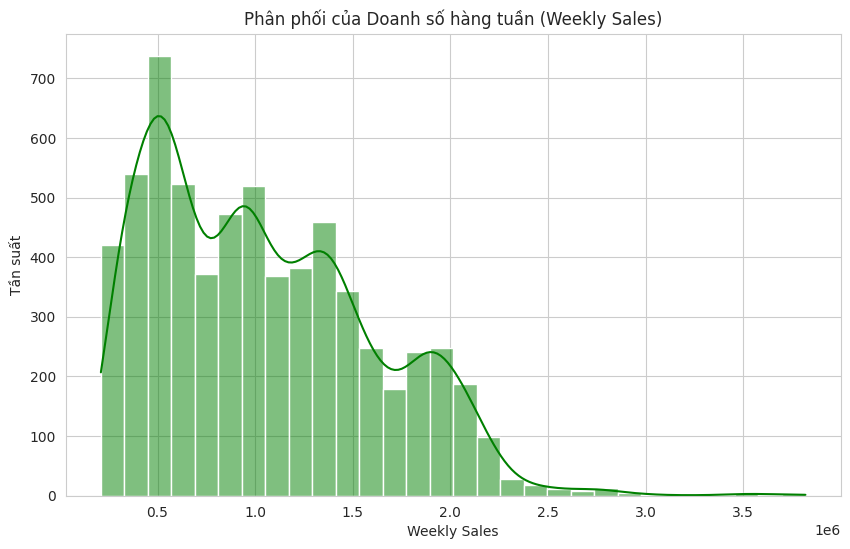

In [167]:
# ========================================================
# 2.2 PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)
# ========================================================

# Chuyển đổi cột Date sang datetime để phân tích xu hướng
df['Date'] = pd.to_datetime(df['Date'], format="%d-%m-%Y")
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Week'] = df['Date'].dt.isocalendar().week

# --- Biểu đồ 1: Phân phối biến mục tiêu (Weekly_Sales) ---
plt.figure(figsize=(10, 6))
sns.histplot(df['Weekly_Sales'], kde=True, color='green', bins=30)
plt.title('Phân phối của Doanh số hàng tuần (Weekly Sales)')
plt.xlabel('Weekly Sales')
plt.ylabel('Tần suất')
plt.savefig('weekly_sales_dist.png', bbox_inches='tight') # Lưu ảnh
plt.show()



/tmp/ipython-input-2922587360.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Holiday_Flag', y='Weekly_Sales', data=df, palette='Set2')


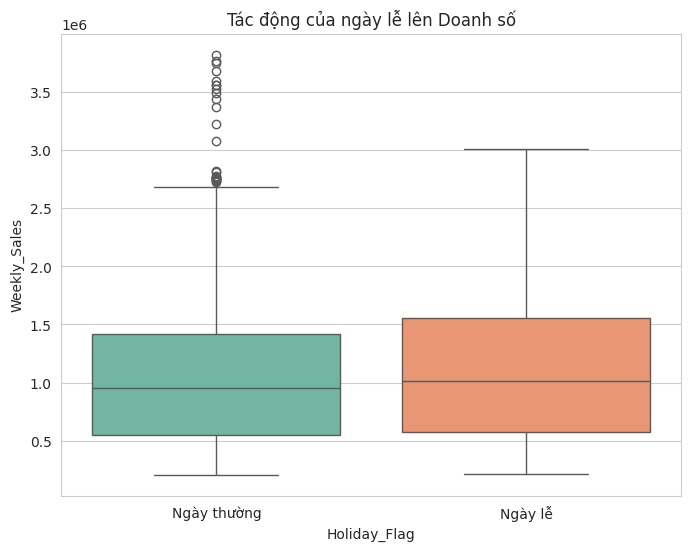

In [168]:
# --- Biểu đồ 2: Tác động của ngày lễ (Boxplot) ---
plt.figure(figsize=(8, 6))
sns.boxplot(x='Holiday_Flag', y='Weekly_Sales', data=df, palette='Set2')
plt.title('Tác động của ngày lễ lên Doanh số')
plt.xticks([0, 1], ['Ngày thường', 'Ngày lễ'])
plt.savefig('holiday_impact.png', bbox_inches='tight') # Lưu ảnh
plt.show()


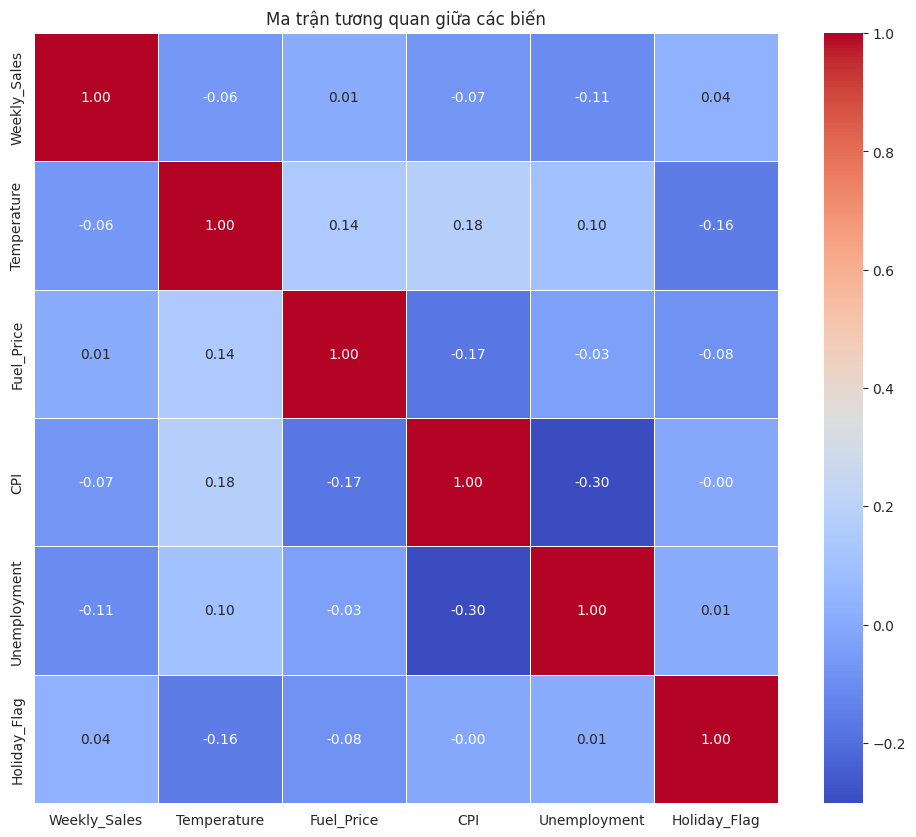

In [169]:
# --- Biểu đồ 3: Ma trận tương quan (Correlation Heatmap) ---
plt.figure(figsize=(12, 10))
# Chọn các cột số để tính tương quan
numeric_cols = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Holiday_Flag']
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Ma trận tương quan giữa các biến')
plt.savefig('correlation_heatmap.png', bbox_inches='tight') # Lưu ảnh
plt.show()


In [170]:
# ========================================================
# 2.3 TIỀN XỬ LÝ DỮ LIỆU (PRE-PROCESSING)
# ========================================================

# 1. Xử lý ngoại lai (Outlier Detection) bằng phương pháp IQR
df_clean = df.copy()
numeric_features = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

print(f"Số lượng mẫu trước khi lọc ngoại lai: {df_clean.shape[0]}")

for col in numeric_features:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Lọc dữ liệu
    df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]

print(f"Số lượng mẫu sau khi lọc ngoại lai: {df_clean.shape[0]}")
print(f"Số lượng mẫu bị loại bỏ: {df.shape[0] - df_clean.shape[0]}")

# 2. Feature Engineering & Encoding

# Xóa cột Date gốc vì đã tách thành Year/Month/Week
if 'Date' in df_clean.columns:
    df_clean = df_clean.drop(['Date'], axis=1)

# Chuyển đổi biến phân loại sang biến giả
categorical_cols = ['Holiday_Flag', 'Year', 'Store']
df_final = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)

print("Kích thước dữ liệu sau khi mã hóa:", df_final.shape)

# 3. Chia tập dữ liệu (Train-Test Split)
X = df_final.drop('Weekly_Sales', axis=1)
y = df_final['Weekly_Sales']

# Chia 80% Train, 20% Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Kích thước tập Train: {X_train.shape}")
print(f"Kích thước tập Test: {X_test.shape}")

Số lượng mẫu trước khi lọc ngoại lai: 6435
Số lượng mẫu sau khi lọc ngoại lai: 5917
Số lượng mẫu bị loại bỏ: 518
Kích thước dữ liệu sau khi mã hóa: (5917, 54)
Kích thước tập Train: (4733, 53)
Kích thước tập Test: (1184, 53)


# **3. CÁC PHƯƠNG PHÁP DỰ BÁO TRUYỀN THỐNG**

In [171]:
# ========================================================
# 3. CÁC PHƯƠNG PHÁP DỰ BÁO TRUYỀN THỐNG
# ========================================================

# Xử lý và biến đổi dữ liệu (Data Manipulation - Scaling)
# Sử dụng StandardScaler để đưa dữ liệu về cùng phân phối chuẩn (mean=0, std=1)
scaler = StandardScaler()

# Fit trên tập train và transform cả train/test để tránh rò rỉ dữ liệu (data leakage)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Chuyển lại thành DataFrame để dễ xử lý
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print("Đã hoàn thành chuẩn hóa dữ liệu (StandardScaler).")

# Lựa chọn đặc trưng (Feature Selection - RFE)
# Sử dụng Recursive Feature Elimination (RFE) để chọn ra các biến quan trọng nhất
# Giả sử ta muốn giữ lại khoảng 20 đặc trưng quan trọng nhất để giảm nhiễu
print("Đang thực hiện lựa chọn đặc trưng (RFE)...")

lm = LinearRegression()
# Chọn top 20 đặc trưng
rfe = RFE(lm, n_features_to_select=20)
rfe = rfe.fit(X_train_scaled, y_train)

# Lọc tập dữ liệu theo các đặc trưng đã chọn
col_supported = X_train_scaled.columns[rfe.support_]
X_train_rfe = X_train_scaled[col_supported]
X_test_rfe = X_test_scaled[col_supported]

print(f"Số lượng đặc trưng được chọn: {len(col_supported)}")
print("Các đặc trưng tiêu biểu:", list(col_supported[:5]), "...")


Đã hoàn thành chuẩn hóa dữ liệu (StandardScaler).
Đang thực hiện lựa chọn đặc trưng (RFE)...
Số lượng đặc trưng được chọn: 20
Các đặc trưng tiêu biểu: ['CPI', 'Month', 'Week', 'Store_3', 'Store_4'] ...


In [172]:
# Huấn luyện và Đánh giá các mô hình (Models Training)
# Hàm đánh giá chung
def evaluate_model(model, X_train, y_train, X_test, y_test, model_name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    print(f"--- {model_name} ---")
    print(f"RMSE: {rmse:,.2f}")
    print(f"R2 Score: {r2:.4f}")
    return {"Model": model_name, "RMSE": rmse, "R2": r2, "MAE": mae}

results = []

# 3.1 Hồi quy tuyến tính đa biến (Multiple Linear Regression)
lr = LinearRegression()
results.append(evaluate_model(lr, X_train_rfe, y_train, X_test_rfe, y_test, "Linear Regression"))

# 3.2 Hồi quy Lasso (L1 Regularization)
lasso = Lasso(alpha=0.1) # Alpha là tham số điều chuẩn
results.append(evaluate_model(lasso, X_train_rfe, y_train, X_test_rfe, y_test, "Lasso Regression"))

# 3.3 Hồi quy Ridge (L2 Regularization)
ridge = Ridge(alpha=1.0)
results.append(evaluate_model(ridge, X_train_rfe, y_train, X_test_rfe, y_test, "Ridge Regression"))

# 3.4 Hồi quy Elastic Net
enet = ElasticNet(alpha=0.1, l1_ratio=0.5)
results.append(evaluate_model(enet, X_train_rfe, y_train, X_test_rfe, y_test, "Elastic Net"))

# 3.5 Hồi quy đa thức (Polynomial Regression - Degree 2)
print("Đang huấn luyện Polynomial Regression (Degree 2)...")
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train_rfe)
X_test_poly = poly.transform(X_test_rfe)

poly_reg = LinearRegression()
results.append(evaluate_model(poly_reg, X_train_poly, y_train, X_test_poly, y_test, "Polynomial Regression"))
# 4. Trực quan hóa kết quả so sánh
df_results = pd.DataFrame(results)

--- Linear Regression ---
RMSE: 288,862.05
R2 Score: 0.7368
--- Lasso Regression ---
RMSE: 288,862.24
R2 Score: 0.7368
--- Ridge Regression ---
RMSE: 288,892.84
R2 Score: 0.7367
--- Elastic Net ---
RMSE: 292,859.57
R2 Score: 0.7294
Đang huấn luyện Polynomial Regression (Degree 2)...
--- Polynomial Regression ---
RMSE: 283,732.41
R2 Score: 0.7460


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.042e+14, tolerance: 1.427e+11
  model = cd_fast.enet_coordinate_descent(


/tmp/ipython-input-1693662498.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="RMSE", y="Model", data=df_results.sort_values("RMSE"), palette="viridis")


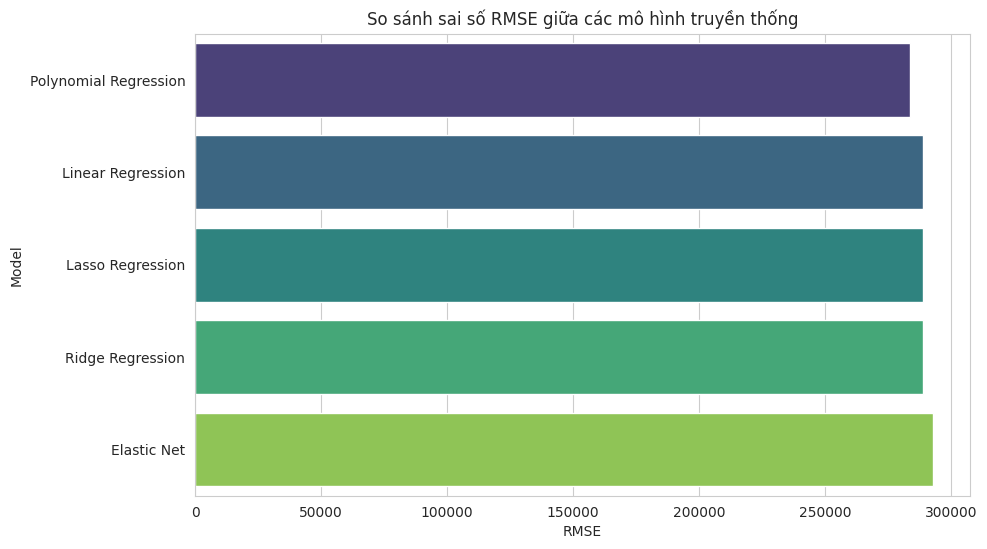

In [173]:
# Vẽ biểu đồ RMSE
plt.figure(figsize=(10, 6))
sns.barplot(x="RMSE", y="Model", data=df_results.sort_values("RMSE"), palette="viridis")
plt.title("So sánh sai số RMSE giữa các mô hình truyền thống")
plt.xlabel("RMSE")
plt.savefig("traditional_models_rmse.png", bbox_inches='tight')
plt.show()


/tmp/ipython-input-1087813389.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="R2", y="Model", data=df_results.sort_values("R2", ascending=False), palette="magma")


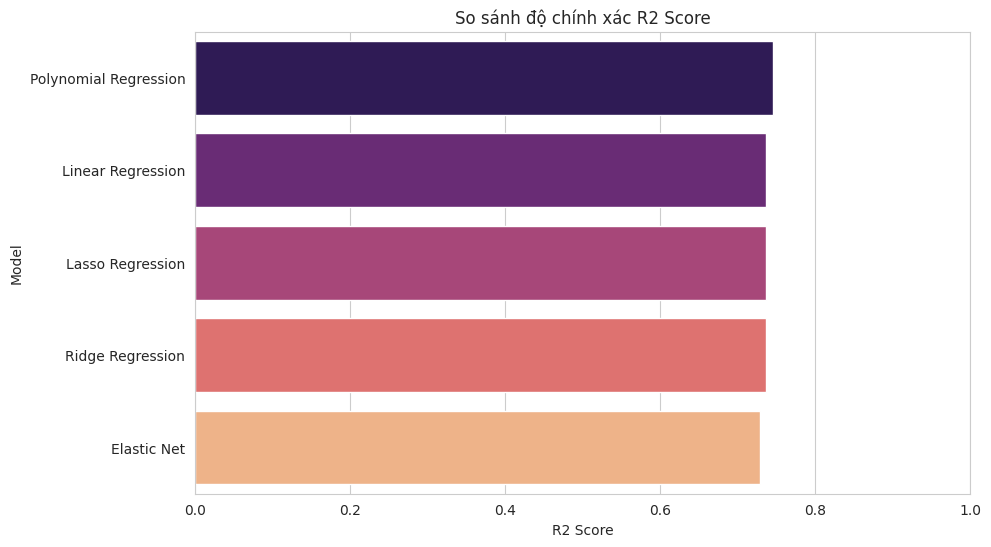

In [174]:
# Vẽ biểu đồ R2
plt.figure(figsize=(10, 6))
sns.barplot(x="R2", y="Model", data=df_results.sort_values("R2", ascending=False), palette="magma")
plt.title("So sánh độ chính xác R2 Score")
plt.xlabel("R2 Score")
plt.xlim(0, 1) # Giới hạn trục x từ 0 đến 1 nếu R2 dương
plt.savefig("traditional_models_r2.png", bbox_inches='tight')
plt.show()


In [175]:
# Hiển thị bảng kết quả
print("\nBảng tổng hợp kết quả:")
print(df_results)


Bảng tổng hợp kết quả:
                   Model           RMSE        R2            MAE
0      Linear Regression  288862.046948  0.736762  201032.962766
1       Lasso Regression  288862.236783  0.736761  201032.979323
2       Ridge Regression  288892.836046  0.736706  201047.414755
3            Elastic Net  292859.572245  0.729425  207387.672035
4  Polynomial Regression  283732.411769  0.746028  193399.357580


# **4. DỰ BÁO CHUỖI THỜI GIAN THỐNG KÊ**

In [176]:
# ========================================================
# 4: DỰ BÁO CHUỖI THỜI GIAN THỐNG KÊ
# ========================================================

# 1. Chuẩn bị dữ liệu chuỗi thời gian
# Gom nhóm theo ngày để tạo chuỗi thời gian tổng doanh số
ts_data = df.groupby('Date')['Weekly_Sales'].sum().reset_index()
ts_data = ts_data.set_index('Date')
ts_data.index.freq = 'W-FRI' # Thiết lập tần suất theo tuần (thứ 6)

# Chia Train/Test
train_size = int(len(ts_data) * 0.8)
train_ts = ts_data.iloc[:train_size]
test_ts = ts_data.iloc[train_size:]

print(f"Train size: {len(train_ts)} weeks")
print(f"Test size: {len(test_ts)} weeks")

# Hàm đánh giá
def evaluate_ts_model(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {model_name} ---")
    print(f"RMSE: {rmse:,.2f}")
    print(f"MAE: {mae:,.2f}")
    return {"Model": model_name, "RMSE": rmse, "MAE": mae, "R2": r2}

results_ts = []


Train size: 114 weeks
Test size: 29 weeks


In [177]:
# ========================================================
# 4.1 MOVING AVERAGE (Trung bình trượt)
# ========================================================
# Sử dụng cửa sổ trượt (window) là 4 tuần (1 tháng)
window_size = 4
# Dự báo cho tập test: Lấy giá trị trung bình của window_size tuần trước đó
history = list(train_ts['Weekly_Sales'])
predictions_ma = []
for t in range(len(test_ts)):
    ma = np.mean(history[-window_size:])
    predictions_ma.append(ma)
    history.append(test_ts.iloc[t]['Weekly_Sales'])

results_ts.append(evaluate_ts_model(test_ts['Weekly_Sales'], predictions_ma, "Moving Average (Window=4)"))


--- Moving Average (Window=4) ---
RMSE: 1,901,638.14
MAE: 1,591,869.67


In [178]:
# ========================================================
# 4.2 SIMPLE EXPONENTIAL SMOOTHING (SES)
# ========================================================
# Phù hợp cho dữ liệu không có xu hướng và mùa vụ rõ ràng
ses_model = SimpleExpSmoothing(train_ts['Weekly_Sales']).fit(optimized=True)
pred_ses = ses_model.forecast(len(test_ts))

results_ts.append(evaluate_ts_model(test_ts['Weekly_Sales'], pred_ses, "Simple Exp Smoothing"))


--- Simple Exp Smoothing ---
RMSE: 2,684,804.94
MAE: 2,287,557.59


In [179]:
# ========================================================
# 4.3 DOUBLE EXPONENTIAL SMOOTHING (Holt's Linear)
# ========================================================
# Có thêm thành phần Xu hướng (Trend)
# Damped = True để giảm xu hướng tăng vô tận
holt_model = ExponentialSmoothing(
    train_ts['Weekly_Sales'],
    trend='add',
    damped_trend=True,
    seasonal=None
).fit(optimized=True)
pred_holt = holt_model.forecast(len(test_ts))

results_ts.append(evaluate_ts_model(test_ts['Weekly_Sales'], pred_holt, "Double Exp Smoothing (Damped)"))


--- Double Exp Smoothing (Damped) ---
RMSE: 1,812,553.73
MAE: 1,362,011.59


In [180]:
# ========================================================
# 4.4 TRIPLE EXPONENTIAL SMOOTHING (Holt-Winters)
# ========================================================
# Quan trọng nhất: Có Trend + Seasonality
# Seasonal_periods = 52 (Dữ liệu tuần, chu kỳ 1 năm = 52 tuần)
# Seasonal = 'mul' (Multiplicative) thường tốt hơn cho bán lẻ khi biên độ dao động tăng theo doanh số
hw_model = ExponentialSmoothing(
    train_ts['Weekly_Sales'],
    trend='add',
    damped_trend=True,
    seasonal='mul',
    seasonal_periods=52
).fit(optimized=True)
pred_hw = hw_model.forecast(len(test_ts))

results_ts.append(evaluate_ts_model(test_ts['Weekly_Sales'], pred_hw, "Holt-Winters (Triple)"))


--- Holt-Winters (Triple) ---
RMSE: 1,405,218.11
MAE: 1,094,207.69


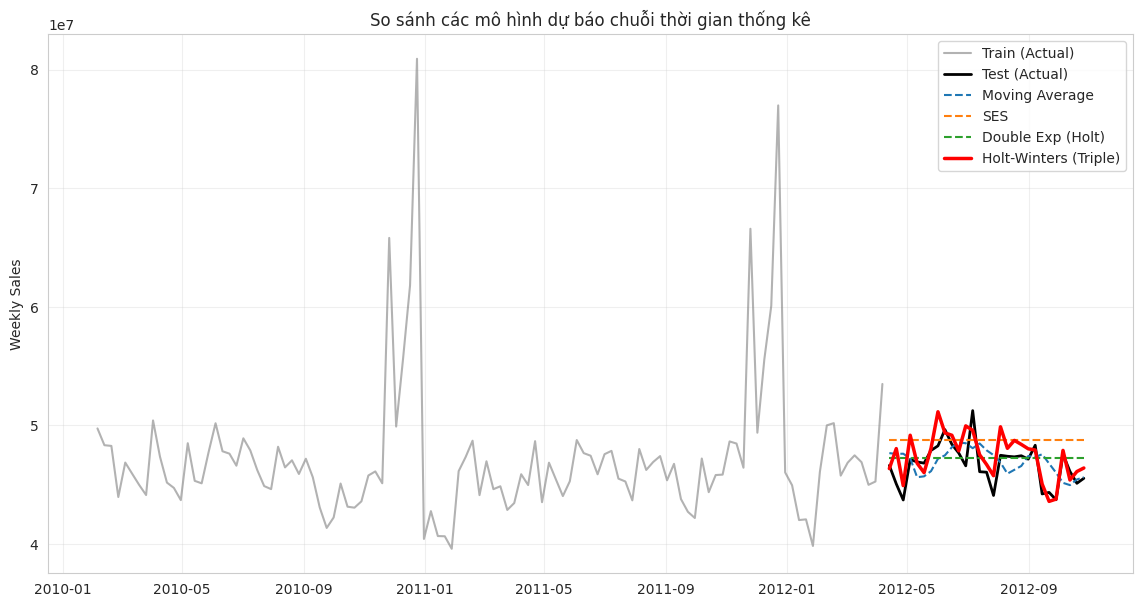

In [181]:
# ========================================================
# VẼ BIỂU ĐỒ & SO SÁNH
# ========================================================

plt.figure(figsize=(14, 7))
plt.plot(train_ts.index, train_ts['Weekly_Sales'], label='Train (Actual)', color='gray', alpha=0.6)
plt.plot(test_ts.index, test_ts['Weekly_Sales'], label='Test (Actual)', color='black', linewidth=2)
# Vẽ các đường dự báo
plt.plot(test_ts.index, predictions_ma, label='Moving Average', linestyle='--')
plt.plot(test_ts.index, pred_ses, label='SES', linestyle='--')
plt.plot(test_ts.index, pred_holt, label='Double Exp (Holt)', linestyle='--')
plt.plot(test_ts.index, pred_hw, label='Holt-Winters (Triple)', color='red', linewidth=2.5)
plt.title('So sánh các mô hình dự báo chuỗi thời gian thống kê')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('statistical_forecast_comparison.png', bbox_inches='tight')
plt.show()



In [182]:
# Hiển thị bảng kết quả
df_results_ts = pd.DataFrame(results_ts)
print("\nBảng tổng hợp kết quả (Statistical Models):")
print(df_results_ts)


Bảng tổng hợp kết quả (Statistical Models):
                           Model          RMSE           MAE        R2
0      Moving Average (Window=4)  1.901638e+06  1.591870e+06 -0.207210
1           Simple Exp Smoothing  2.684805e+06  2.287558e+06 -1.406315
2  Double Exp Smoothing (Damped)  1.812554e+06  1.362012e+06 -0.096753
3          Holt-Winters (Triple)  1.405218e+06  1.094208e+06  0.340804


# **5. DỰ BÁO BẰNG MACHINE LEARING**

In [183]:
# Hàm đánh giá
def evaluate_ml(y_true, y_pred, model_name, time_taken):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"Model: {model_name:<35} | RMSE: {rmse:,.0f} | R2: {r2:.4f} | Time: {time_taken:.2f}s")
    return {"Model": model_name, "RMSE": rmse, "R2": r2, "Time": time_taken}

# Hàm chạy Decentralized
def run_decentralized(model_base, model_name, X_tr, y_tr, X_te, y_te):
    print(f"--- Running Decentralized {model_name}... ---")
    start = time.time()
    store_cols = [c for c in X_tr.columns if 'Store_' in c]
    y_pred_full = pd.Series(index=y_te.index, dtype='float64')

    # 1. Store columns
    for col in store_cols:
        mask_tr = X_tr[col] == 1
        mask_te = X_te[col] == 1
        if mask_tr.sum() > 0 and mask_te.sum() > 0:
            model_clone = clone(model_base)
            model_clone.fit(X_tr[mask_tr], y_tr[mask_tr])
            preds = model_clone.predict(X_te[mask_te])
            y_pred_full.loc[mask_te] = preds

    # 2. Reference store
    mask_tr_ref = (X_tr[store_cols].sum(axis=1) == 0)
    mask_te_ref = (X_te[store_cols].sum(axis=1) == 0)
    if mask_tr_ref.sum() > 0 and mask_te_ref.sum() > 0:
        model_clone = clone(model_base)
        model_clone.fit(X_tr[mask_tr_ref], y_tr[mask_tr_ref])
        y_pred_full.loc[mask_te_ref] = model_clone.predict(X_te[mask_te_ref])

    y_pred_full.fillna(y_tr.mean(), inplace=True)
    end = time.time()
    return evaluate_ml(y_te, y_pred_full, f"Decentralized {model_name}", end - start)

ml_results = []
print("Đã khởi tạo xong")

Đã khởi tạo xong



=== 5.1 DECISION TREE ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Params (Centralized): {'min_samples_split': 29, 'min_samples_leaf': 18, 'max_features': 'sqrt', 'max_depth': None}
Model: Centralized Decision Tree           | RMSE: 201,230 | R2: 0.8723 | Time: 0.57s


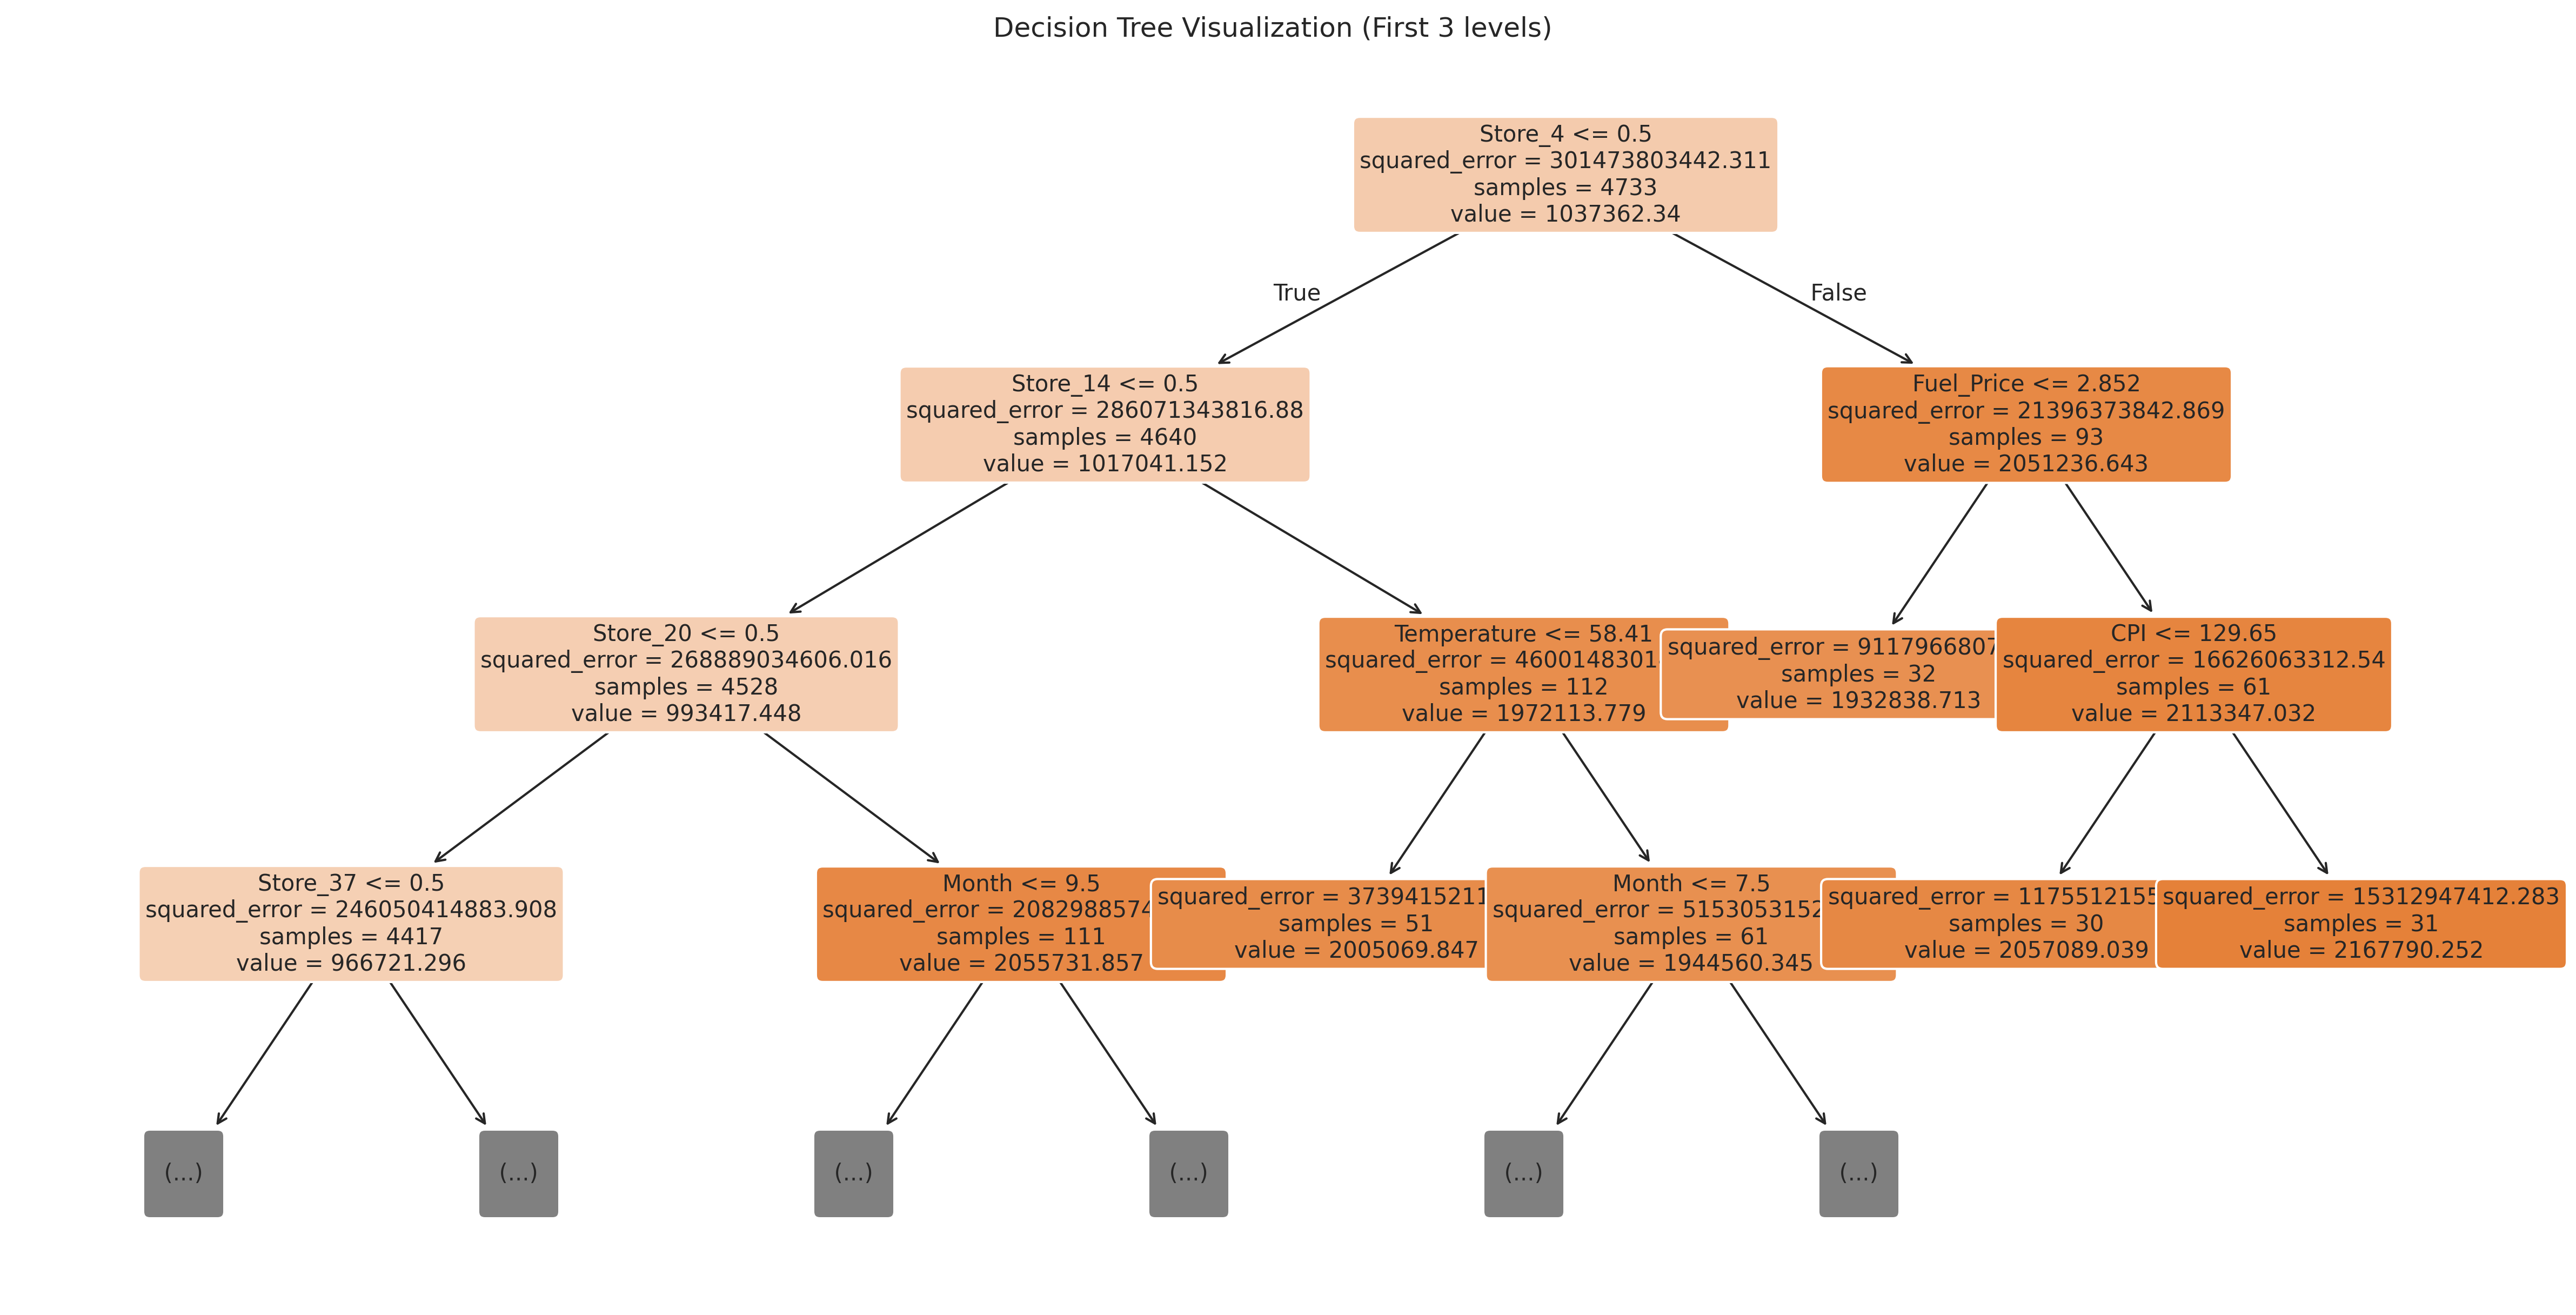

--- Running Decentralized Decision Tree... ---
Model: Decentralized Decision Tree         | RMSE: 117,882 | R2: 0.9562 | Time: 0.31s


In [184]:
# --- DECISION TREE ---
print("\n=== 5.1 DECISION TREE ===")

# 1. Tối ưu hóa mô hình Tập trung (Centralized) bằng RandomizedSearchCV
param_dist_dt = {
    'max_depth': list(range(5, 20)) + [None],
    'min_samples_split': range(10, 30),
    'min_samples_leaf': range(5, 20),
    'max_features': ['sqrt', 'log2', None]
}

dt = DecisionTreeRegressor(random_state=42)
dt_search = RandomizedSearchCV(dt, param_dist_dt, cv=3, n_iter=20,
                               scoring='neg_root_mean_squared_error', n_jobs=-1, verbose=1)

start = time.time()
dt_search.fit(X_train, y_train)
best_dt = dt_search.best_estimator_
y_pred_dt_cen = best_dt.predict(X_test)
end = time.time()

print(f"Best Params (Centralized): {dt_search.best_params_}")
ml_results.append(evaluate_ml(y_test, y_pred_dt_cen, "Centralized Decision Tree", end - start))

# 2. Vẽ cây (Visualization)
plt.figure(figsize=(20, 10), dpi=300)

plot_tree(best_dt, max_depth=3, feature_names=list(X_train.columns),
          filled=True, rounded=True, fontsize=10)

plt.title("Decision Tree Visualization (First 3 levels)")
plt.savefig('decision_tree_viz.png', bbox_inches='tight')
plt.show()

# 3. Decentralized
# Dùng bộ tham số điều chỉnh cho Decentralized để tránh overfitting trên dữ liệu ít
dt_decentral = DecisionTreeRegressor(max_depth=10, min_samples_leaf=10, random_state=42)
ml_results.append(run_decentralized(dt_decentral, "Decision Tree", X_train, y_train, X_test, y_test))

In [185]:
# --- RANDOM FOREST ---
print("\n=== 5.2 RANDOM FOREST ===")

# 1. Tối ưu hóa mô hình Tập trung (Centralized)
param_dist_rf = {
    'n_estimators': [50, 100],
    'max_depth': list(range(10, 25)) + [None],
    'min_samples_split': range(5, 20),
    'min_samples_leaf': range(2, 10),
    'max_features': ['sqrt', 0.5, None],
    'bootstrap': [True],
    'max_samples': [0.7, 0.9, None]
}

rf = RandomForestRegressor(random_state=42, n_jobs=-1)
rf_search = RandomizedSearchCV(rf, param_dist_rf, cv=3, n_iter=10, # n_iter=10 để test nhanh
                               scoring='neg_root_mean_squared_error', n_jobs=-1, verbose=1)

start = time.time()
rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_
y_pred_rf_cen = best_rf.predict(X_test)
end = time.time()

print(f"Best Params (Centralized): {rf_search.best_params_}")
ml_results.append(evaluate_ml(y_test, y_pred_rf_cen, "Centralized Random Forest", end - start))

# 2. Decentralized RF
rf_decentral = RandomForestRegressor(n_estimators=100, max_depth=15,
                                     min_samples_leaf=5, max_features='sqrt',
                                     n_jobs=-1, random_state=42)
ml_results.append(run_decentralized(rf_decentral, "Random Forest", X_train, y_train, X_test, y_test))


=== 5.2 RANDOM FOREST ===
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Params (Centralized): {'n_estimators': 100, 'min_samples_split': 19, 'min_samples_leaf': 3, 'max_samples': 0.9, 'max_features': 'sqrt', 'max_depth': 24, 'bootstrap': True}
Model: Centralized Random Forest           | RMSE: 169,126 | R2: 0.9098 | Time: 14.37s
--- Running Decentralized Random Forest... ---
Model: Decentralized Random Forest         | RMSE: 122,043 | R2: 0.9530 | Time: 7.04s


In [186]:
# --- GRADIENT BOOSTING ---
print("\n=== 5.3 GRADIENT BOOSTING ===")

# 1. Tối ưu hóa mô hình Tập trung
# Gradient Boosting cần learning_rate thấp và nhiều cây
param_dist_gb = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'min_samples_leaf': [5, 10],
    'subsample': [0.8, 1.0]
}

gb = GradientBoostingRegressor(random_state=42)
gb_search = RandomizedSearchCV(gb, param_dist_gb, cv=3, n_iter=10,
                               scoring='neg_root_mean_squared_error', n_jobs=-1, verbose=1)

start = time.time()
gb_search.fit(X_train, y_train)
best_gb = gb_search.best_estimator_
y_pred_gb_cen = best_gb.predict(X_test)
end = time.time()

print(f"Best Params (Centralized): {gb_search.best_params_}")
ml_results.append(evaluate_ml(y_test, y_pred_gb_cen, "Centralized Gradient Boosting", end - start))

# 2. Decentralized GB
# Cần learning rate nhỏ và depth thấp để tránh overfitting trên dữ liệu ít của từng store
gb_decentral = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05,
                                         max_depth=3, subsample=0.8, random_state=42)
ml_results.append(run_decentralized(gb_decentral, "Gradient Boosting", X_train, y_train, X_test, y_test))


=== 5.3 GRADIENT BOOSTING ===
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Params (Centralized): {'subsample': 1.0, 'n_estimators': 200, 'min_samples_leaf': 10, 'max_depth': 5, 'learning_rate': 0.2}
Model: Centralized Gradient Boosting       | RMSE: 88,758 | R2: 0.9751 | Time: 38.37s
--- Running Decentralized Gradient Boosting... ---
Model: Decentralized Gradient Boosting     | RMSE: 103,251 | R2: 0.9664 | Time: 3.69s


In [187]:
# ========================================================
# 5.4 & 5.5: CLUSTERING TECHNIQUES (TỐI ƯU HÓA)
# ========================================================

print("\n=== BẮT ĐẦU QUY TRÌNH PHÂN CỤM & DỰ BÁO ===")

# --- BƯỚC 1: TẠO ĐẶC TRƯNG PHÂN CỤM (MEAN & STD) ---
agg_dict = {
    'Weekly_Sales': ['mean', 'std'],
    'CPI': ['mean'],
    'Unemployment': ['mean']
}

# Kiểm tra xem cột Size có tồn tại không, nếu có thì mới thêm vào
if 'Size' in df_clean.columns:
    agg_dict['Size'] = ['mean']

store_features = df_clean.groupby('Store').agg(agg_dict).reset_index()

# Làm phẳng MultiIndex columns
# Tự động tạo tên cột dựa trên dictionary để tránh lỗi lệch số lượng cột
new_cols = ['Store']
for col in agg_dict.keys():
    for stat in agg_dict[col]:
        if col == 'Weekly_Sales':
            new_cols.append(f"Sales_{stat.capitalize()}") # Sales_Mean, Sales_Std
        else:
            new_cols.append(f"{col}_{stat.capitalize()}") # CPI_Mean, Unemployment_Mean...

store_features.columns = new_cols

# Chuẩn hóa dữ liệu
scaler_clus = MinMaxScaler()
# Lấy tất cả các cột trừ cột 'Store' để đưa vào phân cụm
feature_cols = [c for c in store_features.columns if c != 'Store']
X_clus_scaled = scaler_clus.fit_transform(store_features[feature_cols])

print("Các đặc trưng được dùng để phân cụm:", feature_cols)

# Hàm hỗ trợ train model theo cluster labels
def train_eval_clusters(labels, X_tr, y_tr, X_te, y_te, algorithm_name):
    unique_labels = np.unique(labels)
    y_pred_total = pd.Series(index=y_te.index, dtype='float64')

    # Store columns mapping
    store_cols = [c for c in X_tr.columns if 'Store_' in c]

    # Duyệt qua từng cụm
    for label in unique_labels:
        # Nếu label = -1 (DBSCAN noise), xử lý riêng hoặc gộp chung
        # Ở đây ta lấy danh sách các store thuộc label hiện tại
        current_stores = store_features[labels == label]['Store'].values

        # Tạo mask lọc dữ liệu
        def get_mask(X_data, s_list):
            mask = pd.Series(False, index=X_data.index)
            # Kiểm tra xem có Store tham chiếu (Reference store) không
            if 1 in s_list:
                # Giả định Reference store là khi tất cả cột Store_X đều bằng 0
                if len(store_cols) > 0:
                    mask = mask | (X_data[store_cols].sum(axis=1) == 0)

            for s in s_list:
                c_name = f"Store_{s}"
                if c_name in X_data.columns:
                    mask = mask | (X_data[c_name] == 1)
            return mask

        mask_tr = get_mask(X_tr, current_stores)
        mask_te = get_mask(X_te, current_stores)

        # Chỉ train nếu có dữ liệu trong cụm đó ở cả tập train và test
        if mask_tr.sum() > 0 and mask_te.sum() > 0:
            # Dùng Random Forest làm base learner
            rf = RandomForestRegressor(n_estimators=50, max_depth=15, n_jobs=-1, random_state=42)
            rf.fit(X_tr[mask_tr], y_tr[mask_tr])
            y_pred_total.loc[mask_te] = rf.predict(X_te[mask_te])

    # Điền các giá trị còn thiếu (nếu có store nào không thuộc cụm hoặc lỗi mask) bằng trung bình
    y_pred_total.fillna(y_tr.mean(), inplace=True)
    rmse = np.sqrt(mean_squared_error(y_te, y_pred_total))
    return rmse, y_pred_total

# --- BƯỚC 2: K-MEANS OPTIMIZATION (TÌM K TỐI ƯU) ---
print("\n--- 5.4 Optimizing K-Means ---")
best_k = 2
best_rmse_kmeans = float('inf')
best_pred_kmeans = None
history_kmeans = []

for k in range(2, 10): # Thử từ 2 đến 9 cụm
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_clus_scaled)

    rmse, _ = train_eval_clusters(labels, X_train, y_train, X_test, y_test, "KMeans")
    history_kmeans.append((k, rmse))
    print(f"K={k} | RMSE: {rmse:,.0f}")

    if rmse < best_rmse_kmeans:
        best_rmse_kmeans = rmse
        best_k = k
        best_labels_kmeans = labels

print(f"-> Best K-Means: K={best_k} with RMSE={best_rmse_kmeans:,.0f}")

# Chạy lại 1 lần với best K để lấy y_pred chuẩn cho bảng kết quả
start = time.time()
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
final_labels = kmeans_final.fit_predict(X_clus_scaled)
rmse_final, pred_final_kmeans = train_eval_clusters(final_labels, X_train, y_train, X_test, y_test, "KMeans")
end = time.time()


if 'ml_results' not in globals(): ml_results = []
ml_results.append(evaluate_ml(y_test, pred_final_kmeans, f"K-Means (K={best_k})", end-start))


# --- BƯỚC 3: DBSCAN OPTIMIZATION ---
print("\n--- 5.5 Optimizing DBSCAN ---")
# DBSCAN nhạy cảm với eps. Ta thử nghiệm các giá trị eps khác nhau
eps_values = [0.1, 0.2, 0.3, 0.4, 0.5]
best_rmse_dbscan = float('inf')
best_eps = 0.3
best_pred_dbscan = None

for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=3)
    labels = dbscan.fit_predict(X_clus_scaled)

    # Nếu chỉ ra 1 cụm (hoặc toàn nhiễu -1) thì bỏ qua vì không hiệu quả
    unique_lbls = np.unique(labels)
    if len(unique_lbls) <= 1:
        continue

    rmse, _ = train_eval_clusters(labels, X_train, y_train, X_test, y_test, "DBSCAN")
    n_clusters = len(unique_lbls) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    print(f"Eps={eps} | Clusters: {n_clusters}, Noise: {n_noise} | RMSE: {rmse:,.0f}")

    if rmse < best_rmse_dbscan:
        best_rmse_dbscan = rmse
        best_eps = eps

print(f"-> Best DBSCAN: Eps={best_eps} with RMSE={best_rmse_dbscan:,.0f}")

# Chạy lại Final DBSCAN
start = time.time()
dbscan_final = DBSCAN(eps=best_eps, min_samples=3)
final_labels_db = dbscan_final.fit_predict(X_clus_scaled)
rmse_db, pred_final_db = train_eval_clusters(final_labels_db, X_train, y_train, X_test, y_test, "DBSCAN")
end = time.time()
ml_results.append(evaluate_ml(y_test, pred_final_db, f"DBSCAN (Eps={best_eps})", end-start))




=== BẮT ĐẦU QUY TRÌNH PHÂN CỤM & DỰ BÁO ===
Các đặc trưng được dùng để phân cụm: ['Sales_Mean', 'Sales_Std', 'CPI_Mean', 'Unemployment_Mean']

--- 5.4 Optimizing K-Means ---
K=2 | RMSE: 167,169
K=3 | RMSE: 98,149
K=4 | RMSE: 98,055
K=5 | RMSE: 94,823
K=6 | RMSE: 98,939
K=7 | RMSE: 94,618
K=8 | RMSE: 93,102
K=9 | RMSE: 93,521
-> Best K-Means: K=8 with RMSE=93,102
Model: K-Means (K=8)                       | RMSE: 93,102 | R2: 0.9727 | Time: 1.56s

--- 5.5 Optimizing DBSCAN ---
Eps=0.2 | Clusters: 3, Noise: 29 | RMSE: 129,481
Eps=0.3 | Clusters: 4, Noise: 8 | RMSE: 98,487
Eps=0.4 | Clusters: 2, Noise: 2 | RMSE: 159,878
Eps=0.5 | Clusters: 2, Noise: 1 | RMSE: 168,787
-> Best DBSCAN: Eps=0.3 with RMSE=98,487
Model: DBSCAN (Eps=0.3)                    | RMSE: 98,487 | R2: 0.9694 | Time: 1.23s


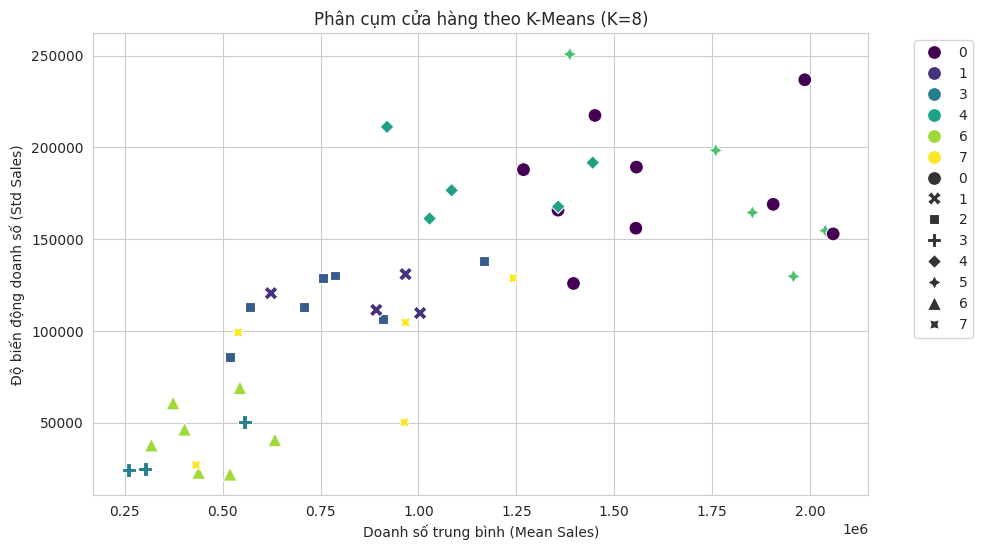

In [188]:
# --- VẼ BIỂU ĐỒ PHÂN CỤM (K-MEANS) ---
store_features['Cluster_KMeans'] = final_labels
plt.figure(figsize=(10, 6))
# Vẽ scatter plot dựa trên 2 đặc trưng quan trọng nhất: Doanh số TB và Độ lệch chuẩn
sns.scatterplot(data=store_features, x='Sales_Mean', y='Sales_Std',
                hue='Cluster_KMeans', palette='viridis', style='Cluster_KMeans', s=100)
plt.title(f'Phân cụm cửa hàng theo K-Means (K={best_k})')
plt.xlabel('Doanh số trung bình (Mean Sales)')
plt.ylabel('Độ biến động doanh số (Std Sales)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('kmeans_clusters.png', bbox_inches='tight')
plt.show()




=== BẢNG TỔNG HỢP KẾT QUẢ ===
                          Model          RMSE       R2      Time
  Centralized Gradient Boosting  88757.632438 0.975147 38.374412
                  K-Means (K=8)  93101.836814 0.972655  1.555758
               DBSCAN (Eps=0.3)  98486.779150 0.969400  1.233654
Decentralized Gradient Boosting 103250.814694 0.966368  3.688923
    Decentralized Decision Tree 117882.273916 0.956161  0.309416
    Decentralized Random Forest 122042.862636 0.953011  7.039106
      Centralized Random Forest 169126.072385 0.909762 14.370785
      Centralized Decision Tree 201230.398179 0.872252  0.573528


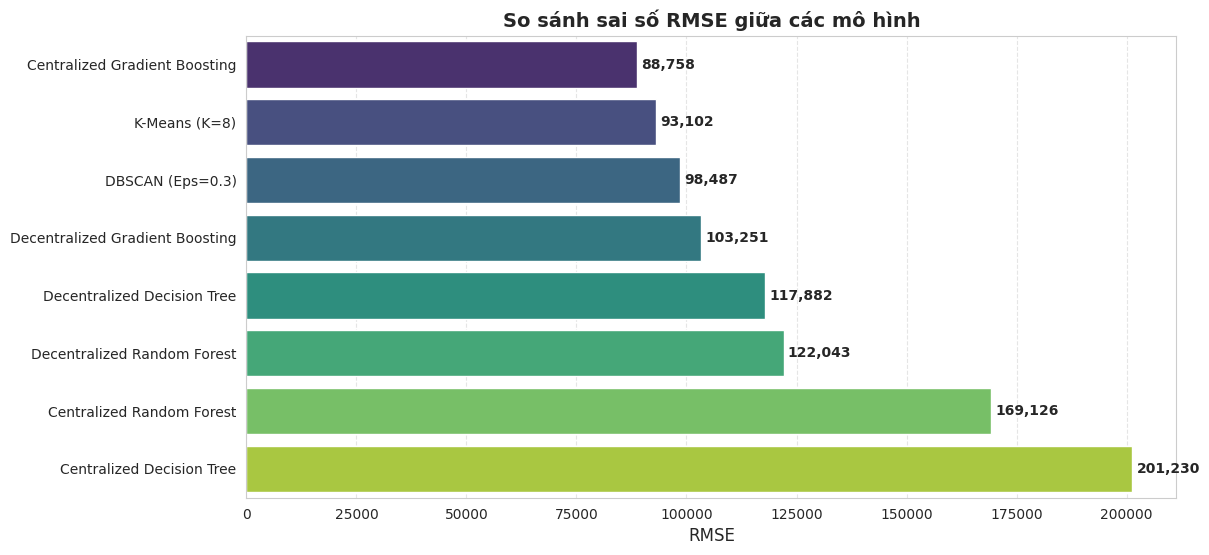

In [189]:
# ========================================================
# TỔNG HỢP KẾT QUẢ CUỐI CÙNG & VẼ BIỂU ĐỒ
# ========================================================

if 'ml_results' in globals() and len(ml_results) > 0:
    df_final = pd.DataFrame(ml_results)

    # Loại bỏ trùng lặp và sắp xếp từ tốt nhất (RMSE thấp nhất) đến tệ nhất
    df_final = df_final.drop_duplicates(subset=['Model'], keep='last')
    df_final = df_final.sort_values("RMSE", ascending=True)

    print("\n=== BẢNG TỔNG HỢP KẾT QUẢ ===")
    print(df_final[['Model', 'RMSE', 'R2', 'Time']].to_string(index=False))

    # Vẽ biểu đồ
    plt.figure(figsize=(12, 6))

    # SỬA LỖI: Thêm hue='Model' và legend=False để tương thích Seaborn mới
    sns.barplot(data=df_final, x='RMSE', y='Model', hue='Model', palette='viridis', legend=False)

    plt.title('So sánh sai số RMSE giữa các mô hình', fontsize=14, fontweight='bold')
    plt.xlabel('RMSE', fontsize=12)
    plt.ylabel('')

    # Thêm số liệu lên cột
    for i, v in enumerate(df_final['RMSE']):
        plt.text(v + 1000, i, f"{v:,.0f}", va='center', fontweight='bold')

    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.savefig('final_ml_comparison.png', bbox_inches='tight', dpi=300)
    plt.show()
else:
    print("Chưa có dữ liệu kết quả (biến ml_results trống).")

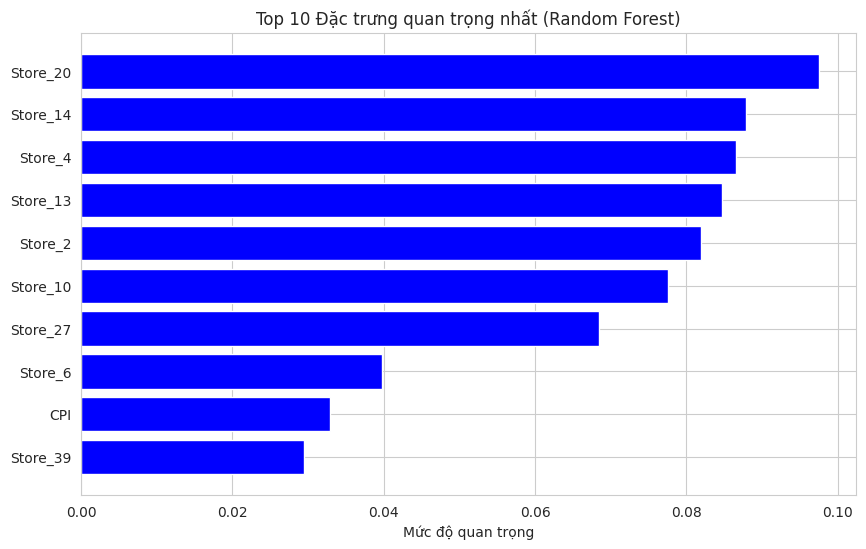

In [190]:
# Vẽ Feature Importance (của Random Forest Centralized)
if 'rf_model' in locals():
    importances = rf_model.feature_importances_
    indices = np.argsort(importances)[-10:] # Top 10

    plt.figure(figsize=(10, 6))
    plt.title('Top 10 Đặc trưng quan trọng nhất (Random Forest)')
    plt.barh(range(len(indices)), importances[indices], color='b', align='center')
    plt.yticks(range(len(indices)), [X_train.columns[i] for i in indices])
    plt.xlabel('Mức độ quan trọng')
    plt.savefig('feature_importance.png', bbox_inches='tight')
    plt.show()

# **6. ĐÁNH GIÁ VÀ TRỰC QUAN HÓA**

In [191]:
# ========================================================
#  6. ĐÁNH GIÁ VÀ TRỰC QUAN HÓA (EVALUATION & VISUALIZATION)
# ========================================================

# ---  CHUẨN BỊ DỮ LIỆU ---
url = 'https://drive.google.com/uc?id=1_5GqH-klzwvqFNcyoi7I2ek_wPcUwduN'
df = pd.read_csv(url)

# Xử lý ngày tháng
df['Date'] = pd.to_datetime(df['Date'], format="%d-%m-%Y")
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Week'] = df['Date'].dt.isocalendar().week

# Xử lý ngoại lai (IQR)
df_clean = df.copy()
for col in ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    df_clean = df_clean[(df_clean[col] >= Q1 - 1.5*IQR) & (df_clean[col] <= Q3 + 1.5*IQR)]

# Encoding
df_final = pd.get_dummies(df_clean.drop('Date', axis=1), columns=['Holiday_Flag', 'Year', 'Store'], drop_first=True)

# --- TỔNG HỢP KẾT QUẢ (6.1) ---
# Dữ liệu từ các chương trước (Hardcoded để vẽ biểu đồ tổng hợp)
# C4 (Time Series) là RMSE tổng hợp (Aggregated), C3/5 là RMSE theo cửa hàng (Store-level)
results_data = {
    'Model': ['Linear Reg (3)', 'Poly Reg Deg2 (3)',
              'Random Forest Decen (5)', 'Decision Tree Decen (5)',
              'Gradient Boosting Cen (5)', 'K-Means Hybrid (5)'],
    'RMSE': [288862, 283732, 122043, 117882, 91301, 93102],
    'R2': [0.7368, 0.7460, 0.9530, 0.9562, 0.9737, 0.9727],
    'Type': ['Traditional', 'Traditional', 'ML (Decentralized)', 'ML (Decentralized)', 'ML (Centralized)', 'ML (Hybrid)']
}
df_res = pd.DataFrame(results_data).sort_values('RMSE')

# --- In bảng số liệu ra màn hình để kiểm tra ---
print("\n=== BẢNG TỔNG HỢP KẾT QUẢ ===")
print(df_res[['Model', 'Type', 'RMSE', 'R2']])


=== BẢNG TỔNG HỢP KẾT QUẢ ===
                       Model                Type    RMSE      R2
4  Gradient Boosting Cen (5)    ML (Centralized)   91301  0.9737
5         K-Means Hybrid (5)         ML (Hybrid)   93102  0.9727
3    Decision Tree Decen (5)  ML (Decentralized)  117882  0.9562
2    Random Forest Decen (5)  ML (Decentralized)  122043  0.9530
1          Poly Reg Deg2 (3)         Traditional  283732  0.7460
0             Linear Reg (3)         Traditional  288862  0.7368


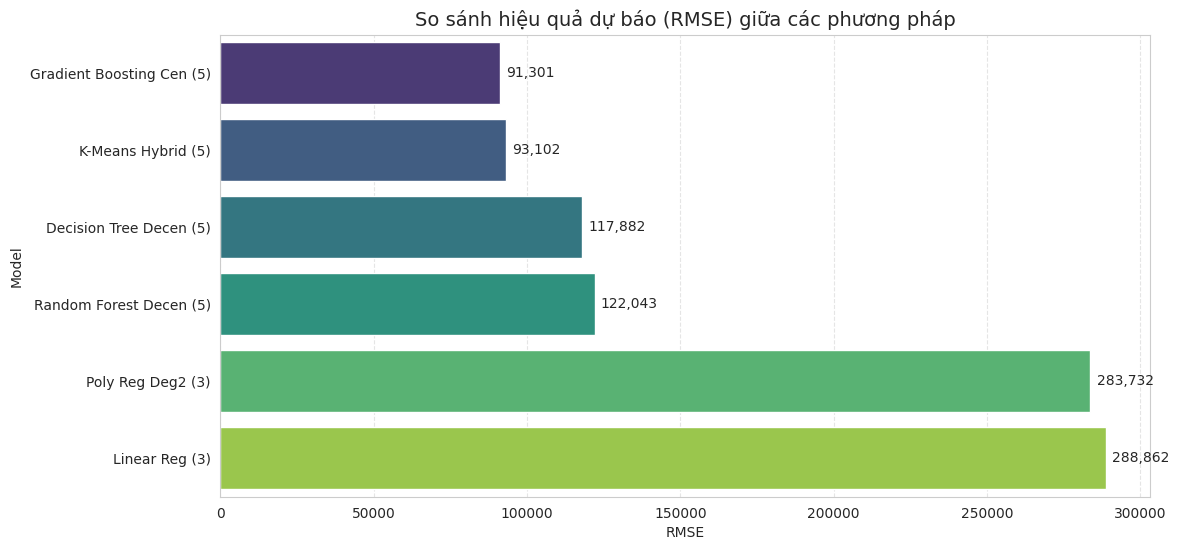

In [192]:
# Vẽ biểu đồ so sánh RMSE
plt.figure(figsize=(12, 6))
sns.barplot(data=df_res, x='RMSE', y='Model', palette='viridis', hue='Model', legend=False)
plt.title('So sánh hiệu quả dự báo (RMSE) giữa các phương pháp', fontsize=14)
plt.xlabel('RMSE')
for i, v in enumerate(df_res['RMSE']):
    plt.text(v + 2000, i, f"{v:,.0f}", va='center')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.savefig('summary_rmse.png', bbox_inches='tight')
plt.show()



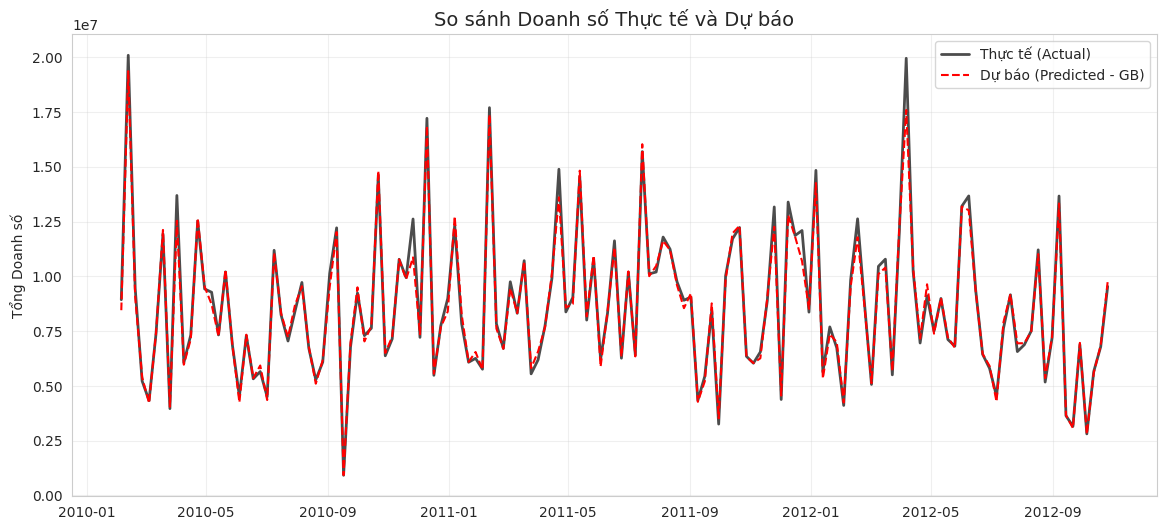

In [193]:
# ---  DỰ BÁO VS THỰC TẾ (6.2) ---
# Huấn luyện lại mô hình tốt nhất (Gradient Boosting Centralized) trên split 80/20
X = df_final.drop('Weekly_Sales', axis=1)
y = df_final['Weekly_Sales']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.2, max_depth=7,
                                     min_samples_leaf=5, subsample=0.8, random_state=42)
gb_model.fit(X_train, y_train)
y_pred = gb_model.predict(X_test)

# Cần lấy lại thông tin Date cho tập Test
test_indices = X_test.index
df_viz = df_clean.loc[test_indices, ['Date', 'Weekly_Sales']].copy()
df_viz['Predicted'] = y_pred
df_viz['Actual'] = y_test

# Gom nhóm theo ngày để vẽ đường xu hướng tổng
df_agg = df_viz.groupby('Date')[['Actual', 'Predicted']].sum().reset_index().sort_values('Date')

plt.figure(figsize=(14, 6))
plt.plot(df_agg['Date'], df_agg['Actual'], label='Thực tế (Actual)', color='black', linewidth=2, alpha=0.7)
plt.plot(df_agg['Date'], df_agg['Predicted'], label='Dự báo (Predicted - GB)', color='red', linestyle='--')
plt.title('So sánh Doanh số Thực tế và Dự báo', fontsize=14)
plt.ylabel('Tổng Doanh số')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('pred_vs_actual.png', bbox_inches='tight')
plt.show()



In [194]:
# --- ĐỘ ỔN ĐỊNH (6.3) ---
# Thử nghiệm với tỷ lệ chia 70/30
X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(X, y, test_size=0.3, random_state=42)

gb_model_70 = GradientBoostingRegressor(n_estimators=100, learning_rate=0.2, max_depth=7,
                                        min_samples_leaf=5, subsample=0.8, random_state=42)
gb_model_70.fit(X_train_70, y_train_70)
y_pred_70 = gb_model_70.predict(X_test_70)

rmse_70 = np.sqrt(mean_squared_error(y_test_70, y_pred_70))
r2_70 = r2_score(y_test_70, y_pred_70)
rmse_80 = df_res[df_res['Model']=='Gradient Boosting Cen (5)']['RMSE'].values[0]
r2_80 = df_res[df_res['Model']=='Gradient Boosting Cen (5)']['R2'].values[0]



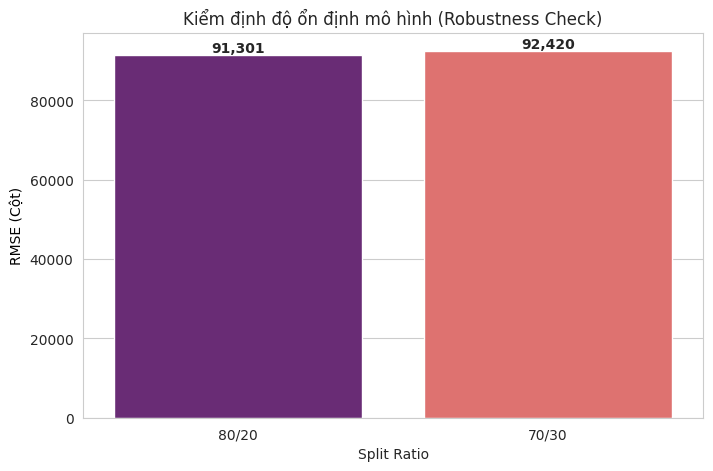


=== KẾT QUẢ ROBUSTNESS ===
  Split Ratio          RMSE        R2
0       80/20  91301.000000  0.973700
1       70/30  92420.266386  0.973319


In [195]:
# Vẽ biểu đồ so sánh Robustness
robust_data = pd.DataFrame({
    'Split Ratio': ['80/20', '70/30'],
    'RMSE': [rmse_80, rmse_70],
    'R2': [r2_80, r2_70]
})

fig, ax1 = plt.subplots(figsize=(8, 5))
sns.barplot(data=robust_data, x='Split Ratio', y='RMSE', palette='magma', ax=ax1, hue='Split Ratio', legend=False)
ax1.set_ylabel('RMSE (Cột)', color='black')
ax1.set_title('Kiểm định độ ổn định mô hình (Robustness Check)')
for i, v in enumerate(robust_data['RMSE']):
    ax1.text(i, v, f"{v:,.0f}", ha='center', va='bottom', fontweight='bold')

plt.savefig('robustness.png', bbox_inches='tight')
plt.show()

print("\n=== KẾT QUẢ ROBUSTNESS ===")
print(robust_data)